# Étape 10.2 : ERC avec une volatilité prévue par GARCH

À l'étape 9, les poids ERC des facteurs utilisent la volatilité **historique** des 60 derniers mois. Ici, on la remplace par la volatilité **prévue pour le mois suivant** par un modèle GARCH, estimé sur les facteurs de Fama et French. Les corrélations restent calculées sur 60 mois. Tout le reste est identique à l'étape 9 : actions, z-scores, sélection, zone tampon, pondération, plafond, frais.

Plan :
1. vérifier que la volatilité des facteurs est prévisible (ACF et PACF des rendements au carré) ;
2. choisir le modèle GARCH ;
3. évaluer ses prévisions de volatilité hors échantillon ;
4. backtester le portefeuille.

## 1. Données et outils de l'étape 9

In [1]:
import io
import zipfile
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import statsmodels.api as sm
from scipy.optimize import minimize
from scipy.stats import norm
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

warnings.filterwarnings("ignore", category=FutureWarning)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = ROOT / "data" / "raw"
FIG = ROOT / "docs" / "figures"

pd.set_option("display.precision", 3)
pd.set_option("display.width", 140)
from arch import arch_model
from statsmodels.graphics.tsaplots import acf, pacf
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch

In [2]:
base = pd.read_csv(ROOT / "data" / "processed" / "zscores_sp500_mensuels.csv.gz")
base["mois"] = pd.PeriodIndex(base["mois"], freq="M")
base = base.set_index(["mois", "ticker"]).sort_index()

ajustes = pd.read_csv(RAW / "sp500_cours_ajustes_mensuels.csv", index_col=0)
ajustes.index = pd.PeriodIndex(ajustes.index.astype(str).str[:7], freq="M")
rendements = ajustes.pct_change(fill_method=None)


def lire_bloc_mensuel(chemin_zip):
    with zipfile.ZipFile(chemin_zip) as z:
        texte = z.read(z.namelist()[0]).decode("latin-1")
    lignes = texte.splitlines()
    debut = next(i for i, l in enumerate(lignes) if l.startswith(","))
    bloc = [lignes[debut]]
    for l in lignes[debut + 1:]:
        if not l.strip() or not l.strip()[0].isdigit():
            break
        bloc.append(l)
    df = pd.read_csv(io.StringIO("\n".join(bloc)), index_col=0)
    df.columns = df.columns.str.strip()
    df.index = pd.PeriodIndex(df.index.astype(str), freq="M")
    return df.astype(float) / 100


facteurs = lire_bloc_mensuel(RAW / "F-F_Research_Data_5_Factors_2x3_CSV.zip").join(
    lire_bloc_mensuel(RAW / "F-F_Momentum_Factor_CSV.zip"), how="inner")
rf = facteurs["RF"]

etf = pd.read_csv(RAW / "cours_mensuels.csv", index_col=0)[["SPY", "RSP"]]
etf.index = pd.PeriodIndex(etf.index, freq="M")
rend_etf = etf.pct_change()

mois = base.index.get_level_values("mois").unique()
print(f"z-scores : {mois[0]} à {mois[-1]}, {len(mois)} mois")

z-scores : 2012-02 à 2026-08, 175 mois


In [3]:
STYLES = {"z_smb": "SMB", "z_hml": "HML", "z_rmw": "RMW", "z_cma": "CMA", "z_mom": "Mom"}
Z = base[list(STYLES)]

In [4]:
def poids_erc(cov):
    # Spinu (2013) : le minimum de 1/2 y'Σy - (1/n) Σ log(y) donne des contributions au risque égales.
    n = len(cov)
    y0 = 1 / np.sqrt(np.diag(cov))
    y = minimize(lambda y: 0.5 * y @ cov @ y - np.log(y).sum() / n, y0,
                 jac=lambda y: cov @ y - 1 / (n * y), bounds=[(1e-10, None)] * n, method="L-BFGS-B").x
    return y / y.sum()


def contributions(w, cov):
    rc = w * (cov @ w)
    return rc / rc.sum()


poids = {}
for m in mois:
    histo = facteurs.loc[:m, list(STYLES.values())].iloc[-60:]
    poids[m] = poids_erc(histo.cov().values)
poids = pd.DataFrame(poids, index=list(STYLES.values())).T

# Contrôle : contributions au risque au dernier mois
cov_fin = facteurs.loc[:mois[-1], list(STYLES.values())].iloc[-60:].cov().values
print("Contributions au risque (dernier mois) :", np.round(contributions(poids.iloc[-1].values, cov_fin), 3))
print("\nPoids ERC des facteurs dans le score, résumé sur la période :")
poids.describe().loc[["mean", "min", "max"]].round(2)

Contributions au risque (dernier mois) : [0.2 0.2 0.2 0.2 0.2]

Poids ERC des facteurs dans le score, résumé sur la période :


,SMB,HML,RMW,CMA,Mom
mean,0.23,0.13,0.30,0.18,0.17
min,0.17,0.08,0.25,0.12,0.08
max,0.32,0.22,0.36,0.23,0.22


In [5]:
def score_final(w):
    # w : DataFrame (mois x facteurs) de poids
    wl = w.reindex(Z.index.get_level_values("mois")).set_axis(Z.index)
    wl.columns = list(STYLES)
    s = (Z.fillna(0) * wl).sum(axis=1)[Z.notna().sum(axis=1) >= 3]
    return s.groupby(level="mois").transform(lambda x: (x - x.mean()) / x.std())


egal = pd.DataFrame(0.2, index=mois, columns=list(STYLES.values()))
scores = pd.DataFrame({"score_equipondere": score_final(egal), "score_erc": score_final(poids)})
print(f"{len(scores):,}".replace(",", " "), "scores (mois, action)")
print(f"Corrélation entre les deux scores : {scores.corr().iloc[0, 1]:.2f}")
scores.to_csv(ROOT / "data" / "processed" / "scores_finaux_sp500.csv.gz", float_format="%.5g")

72 741 scores (mois, action)
Corrélation entre les deux scores : 0.92


In [6]:
capi = base["capitalisation"]
PLAFOND = 0.10


def plafonner(w, plafond=PLAFOND):
    # Aucune action au-dessus du plafond ; l'excédent est redistribué aux autres, au prorata.
    w = w / w.sum()
    while (w > plafond + 1e-12).any():
        trop = w > plafond
        excedent = (w[trop] - plafond).sum()
        w[trop] = plafond
        w[~trop] += excedent * w[~trop] / w[~trop].sum()
    return w


def poids_cibles(score, seuil=0.30, tampon=0.40, ponderation="capi_score"):
    cibles, tenus = {}, set()
    for m in mois[:-1]:
        s = score.xs(m).dropna()
        c = capi.xs(m).reindex(s.index).dropna()
        s = s[c.index]
        rang = s.rank(ascending=False, pct=True)
        selection = set(rang[rang <= seuil].index)
        if tampon:
            selection |= set(rang[rang <= tampon].index) & tenus
        selection = sorted(selection)
        tenus = set(selection)
        if ponderation == "egale":
            w = pd.Series(1.0, index=selection)
        elif ponderation == "capi":
            w = c[selection]
        else:
            w = c[selection] * (1 + s[selection]).clip(lower=0)
        cibles[m] = plafonner(w)
    return cibles

In [7]:
def backtest(cibles, frais=0.0010):
    lignes, derive, manquants = {}, pd.Series(dtype=float), 0
    for m, w in cibles.items():
        rotation = w.subtract(derive, fill_value=0).abs().sum()
        r = rendements.loc[m + 1].reindex(w.index)
        manquants += int(r.isna().sum())
        r = r.fillna(0)
        brut = float((w * r).sum())
        lignes[m + 1] = {"brut": brut, "rotation": rotation, "net": brut - frais * rotation}
        derive = w * (1 + r)
        derive = derive / derive.sum()
    sortie = pd.DataFrame(lignes).T
    sortie.attrs["manquants"] = manquants
    return sortie


def univers_capi():
    return {m: capi.xs(m).dropna() / capi.xs(m).dropna().sum() for m in mois[:-1]}

In [8]:
def test_moyenne(a):
    m = sm.OLS(a.values, np.ones(len(a))).fit(cov_type="HAC", cov_kwds={"maxlags": 6})
    return m.params[0], m.tvalues[0], m.pvalues[0]


def indices_bootstrap(n, bloc_moyen, rng):
    idx = np.empty(n, dtype=int)
    idx[0] = rng.integers(n)
    for i in range(1, n):
        idx[i] = rng.integers(n) if rng.random() < 1 / bloc_moyen else (idx[i - 1] + 1) % n
    return idx


def sharpe(x, r_f):
    e = x - r_f
    return e.mean() / e.std() * np.sqrt(12)


def bootstrap(strat, bench, n_tirages=5000, bloc_moyen=6, graine=0):
    rng = np.random.default_rng(graine)
    s, b, f = strat.values, bench.values, rf.reindex(strat.index).values
    actif, d_sharpe = [], []
    for _ in range(n_tirages):
        i = indices_bootstrap(len(s), bloc_moyen, rng)
        actif.append((s[i] - b[i]).mean() * 12)
        d_sharpe.append(sharpe(s[i], f[i]) - sharpe(b[i], f[i]))
    return np.percentile(actif, [2.5, 97.5]), np.percentile(d_sharpe, [2.5, 97.5])

In [9]:
SURFACE, TEXTE, TEXTE2, GRILLE = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
BLEU, ORANGE, AQUA, JAUNE, MAGENTA, VERT = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"
GRIS = "#8d8c88"

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.family": "DejaVu Sans", "font.size": 10,
    "text.color": TEXTE, "axes.labelcolor": TEXTE2, "xtick.color": TEXTE2, "ytick.color": TEXTE2,
    "axes.edgecolor": GRILLE, "axes.grid": True, "grid.color": GRILLE, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "legend.frameon": False,
})


def sauver(fig, nom):
    fig.savefig(FIG / nom, dpi=200, bbox_inches="tight")


def virgule(fmt):
    return plt.FuncFormatter(lambda v, _: fmt.format(v).replace(".", ",").replace("-", "−"))


COULEURS = {"Score équipondéré": BLEU, "Score ERC": ORANGE, "Univers (capitalisation)": TEXTE2, "SPY": GRIS}

## 2. La volatilité des facteurs est-elle prévisible ?

Si les grosses variations d'un facteur sont suivies d'autres grosses variations, la volatilité est **prévisible** à court terme. On le voit sur les **rendements au carré** $\varepsilon_t^2 = (r_t - \bar r)^2$, qui mesurent l'ampleur du mouvement sans son signe :

- **ACF** (autocorrélation) : corrélation entre $\varepsilon_t^2$ et $\varepsilon_{t-h}^2$. Si elle est positive sur plusieurs retards, la volatilité a de la mémoire.
- **PACF** (autocorrélation partielle) : la même chose, une fois retiré l'effet des retards intermédiaires. Elle indique combien de retards un modèle ARCH aurait besoin.
- **Tests** : Ljung-Box sur les 12 premières autocorrélations de $\varepsilon_t^2$, et test ARCH d'Engle (1982) à 12 retards. Hypothèse nulle : aucune dépendance de la volatilité.

Échantillon : juillet 1963 à août 2026 (758 mois). Bandes de confiance à 95 % : $\pm 1{,}96 / \sqrt{T}$.

In [10]:
FACT = list(STYLES.values())
eps2 = (facteurs[FACT] - facteurs[FACT].mean()) ** 2
RETARDS = 24
acfs = pd.DataFrame({k: acf(eps2[k], nlags=RETARDS)[1:] for k in FACT}, index=range(1, RETARDS + 1))
pacfs = pd.DataFrame({k: pacf(eps2[k], nlags=RETARDS, method="ywm")[1:] for k in FACT}, index=range(1, RETARDS + 1))
bande = 1.96 / np.sqrt(len(eps2))

tests_arch = pd.DataFrame({k: {
    "Ljung-Box Q(12)": acorr_ljungbox(eps2[k], [12], return_df=True)["lb_stat"].iloc[0],
    "p-valeur LB": acorr_ljungbox(eps2[k], [12], return_df=True)["lb_pvalue"].iloc[0],
    "test ARCH (12)": het_arch(facteurs[k] - facteurs[k].mean(), nlags=12)[0],
    "p-valeur ARCH": het_arch(facteurs[k] - facteurs[k].mean(), nlags=12)[1],
    "ACF retards 1-6 significatives": int((acfs[k].iloc[:6] > bande).sum()),
    "PACF retards 1-12 significatives": int((pacfs[k].iloc[:12].abs() > bande).sum()),
} for k in FACT}).T
tests_arch.style.format({"Ljung-Box Q(12)": "{:.0f}", "test ARCH (12)": "{:.0f}", "p-valeur LB": "{:.0e}",
                         "p-valeur ARCH": "{:.0e}"})

,Ljung-Box Q(12),p-valeur LB,test ARCH (12),p-valeur ARCH,ACF retards 1-6 significatives,PACF retards 1-12 significatives
SMB,117,3e-19,92,2e-14,3.000000,4.000000
HML,303,1e-57,110,6e-18,6.000000,7.000000
RMW,479,6e-95,215,2e-39,6.000000,7.000000
CMA,380,6e-74,131,3e-22,6.000000,5.000000
Mom,81,3e-12,52,6e-07,3.000000,2.000000


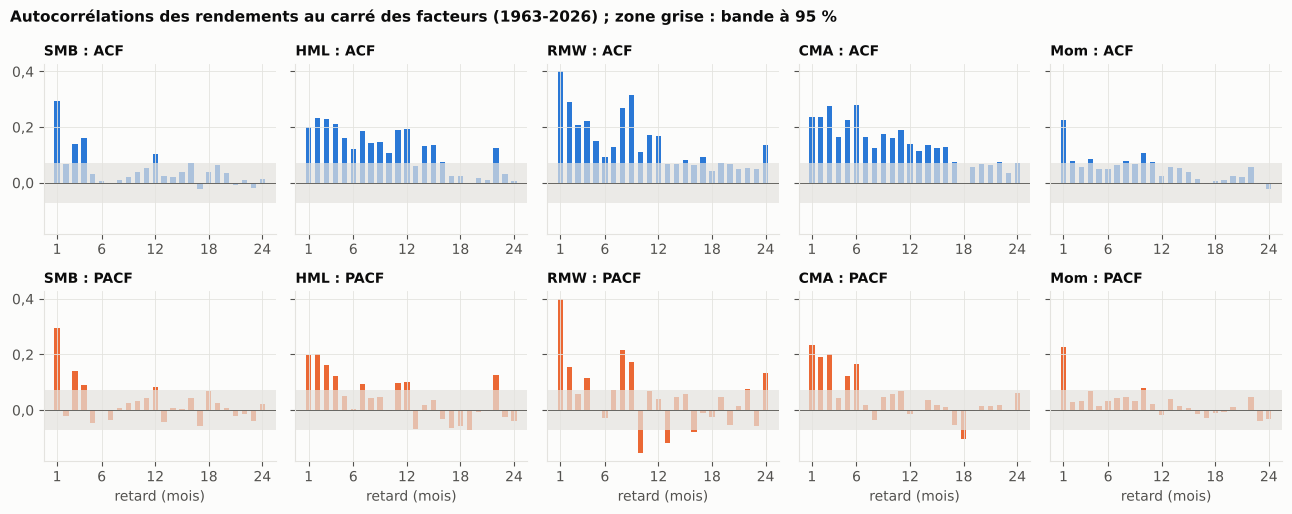

In [11]:
fig, axes = plt.subplots(2, 5, figsize=(13, 5.2), sharey=True)
for j, k in enumerate(FACT):
    for i, (serie, titre) in enumerate([(acfs[k], "ACF"), (pacfs[k], "PACF")]):
        ax = axes[i, j]
        ax.bar(serie.index, serie.values, width=0.6, color=BLEU if i == 0 else ORANGE)
        ax.axhspan(-bande, bande, color=GRILLE, alpha=0.7, lw=0)
        ax.axhline(0, color=TEXTE2, lw=0.6)
        ax.set_title(f"{k} : {titre}", fontsize=10)
        ax.set_xticks([1, 6, 12, 18, 24])
        ax.yaxis.set_major_formatter(virgule("{:.1f}"))
        if i == 1:
            ax.set_xlabel("retard (mois)")
fig.suptitle("Autocorrélations des rendements au carré des facteurs (1963-2026) ; zone grise : bande à 95 %",
             x=0.01, ha="left", fontsize=11, fontweight="bold")
fig.tight_layout()
sauver(fig, "garch_acf_pacf.png")
plt.show()

**Lecture :**
- Les tests rejettent très nettement l'absence de dépendance pour les cinq facteurs.
- L'ACF est positive sur de nombreux retards et décroît lentement : un mois agité annonce d'autres mois agités (**regroupement de la volatilité**).
- La PACF a plusieurs retards significatifs : un modèle ARCH pur aurait besoin de beaucoup de retards. Un **GARCH(1,1)** résume cette longue mémoire avec trois paramètres : il équivaut à un ARCH d'ordre infini à poids décroissants (Bollerslev, 1986).

## 3. Le choix du modèle

Modèle GARCH(p, q) pour chaque facteur :

$$r_t = \mu + \varepsilon_t, \qquad \varepsilon_t = \sigma_t z_t, \qquad \sigma_t^2 = \omega + \sum_{i=1}^{q} \alpha_i \varepsilon_{t-i}^2 + \sum_{j=1}^{p} \beta_j \sigma_{t-j}^2$$

La prévision pour le mois suivant est $\hat\sigma^2_{t+1|t} = \omega + \alpha \varepsilon_t^2 + \beta \sigma_t^2$ (cas GARCH(1,1)).

**Candidats** : ARCH(1), GARCH(1,1), GARCH(2,1), GARCH(1,2), GJR-GARCH(1,1) (effet asymétrique des baisses, Glosten, Jagannathan et Runkle, 1993), EGARCH(1,1), chacun avec des chocs $z_t$ de loi normale ou de Student.

**Critère** : BIC, somme sur les cinq facteurs. Le choix se fait sur **juillet 1963 à décembre 1989** uniquement, avant toute période d'évaluation.

In [12]:
CANDIDATS = {"ARCH(1)": dict(p=1, q=0), "GARCH(1,1)": dict(p=1, q=1), "GARCH(2,1)": dict(p=1, q=2),
             "GARCH(1,2)": dict(p=2, q=1), "GJR-GARCH(1,1)": dict(p=1, o=1, q=1),
             "EGARCH(1,1)": dict(vol="EGARCH", p=1, o=1, q=1)}
LOIS = {"normal": "normale", "t": "Student"}
f_sel = facteurs.loc[:"1989-12", FACT]
lignes = []
for nom, spec in CANDIDATS.items():
    for loi, libelle in LOIS.items():
        ligne = {"modèle": nom, "loi": libelle}
        for k in FACT:
            kw = {"vol": "GARCH", **spec}
            res = arch_model(100 * f_sel[k], mean="Constant", dist=loi, **kw).fit(disp="off", show_warning=False)
            ligne[k] = res.bic
        lignes.append(ligne)
bic = pd.DataFrame(lignes).set_index(["modèle", "loi"])
bic["total"] = bic.sum(axis=1)
bic["écart au meilleur"] = bic["total"] - bic["total"].min()
bic.sort_values("total").style.format("{:.1f}")

L'EGARCH de Student a le plus petit BIC, mais l'écart avec le GARCH(1,1) de Student est faible (environ 2 points par facteur, une différence « positive » mais pas « forte » au sens de Kass et Raftery, 1995). Avant de trancher, on regarde la **stabilité** des deux modèles quand on les ré-estime chaque année (même procédure que la section 4) :

In [13]:
def previsions(spec, debut="1989-12", fin=None, reestimation=12):
    # Prévision de la variance du mois t+1, faite fin t, avec les seules données jusqu'à t.
    # Paramètres ré-estimés chaque décembre sur tout l'historique disponible (fenêtre croissante).
    fin = fin or facteurs.index[-1]
    sortie = {}
    for k in FACT:
        x = 100 * facteurs[k]
        params, valeurs = None, {}
        for m in facteurs.loc[debut:fin].index:
            modele = arch_model(x.loc[:m], mean="Constant", **spec)
            if params is None or m.month == 12:
                params = modele.fit(disp="off", show_warning=False).params
            valeurs[m + 1] = modele.fix(params).forecast(horizon=1, reindex=False).variance.iloc[-1, 0] / 1e4
        sortie[k] = pd.Series(valeurs)
    return pd.DataFrame(sortie)


SPEC_GARCH = dict(vol="GARCH", p=1, q=1, dist="t")
SPEC_EGARCH = dict(vol="EGARCH", p=1, o=1, q=1, dist="t")
prev_garch = previsions(SPEC_GARCH)
prev_egarch = previsions(SPEC_EGARCH)
vol_max = pd.DataFrame({"GARCH(1,1) Student": np.sqrt(12 * prev_garch.max()),
                        "EGARCH(1,1) Student": np.sqrt(12 * prev_egarch.max()),
                        "plus forte vol. réalisée sur 12 mois": facteurs[FACT].rolling(12).std().max() * np.sqrt(12)})
print("Volatilité annualisée maximale prévue entre 1990 et 2026 :")
vol_max.style.format("{:.0%}")

Volatilité annualisée maximale prévue entre 1990 et 2026 :


,"GARCH(1,1) Student","EGARCH(1,1) Student",plus forte vol. réalisée sur 12 mois
SMB,26%,22%,30%
HML,26%,137%,26%
RMW,27%,25%,34%
CMA,20%,18%,17%
Mom,73%,40%,43%


L'EGARCH produit une prévision aberrante pour HML : une fois ré-estimé, il est numériquement instable. Le **GARCH(1,1) de Student** est retenu : presque aussi bon en BIC, plus simple, et toujours stable (la contrainte $\alpha + \beta < 1$ garantit que la variance revient vers son niveau moyen).

Paramètres estimés sur 1963-1989, et contrôle des résidus : si le modèle a capté la dépendance, les résidus standardisés au carré $z_t^2$ ne doivent plus être autocorrélés.

In [14]:
lignes = {}
for k in FACT:
    res = arch_model(100 * f_sel[k], mean="Constant", **SPEC_GARCH).fit(disp="off", show_warning=False)
    p = res.params
    persistance = p["alpha[1]"] + p["beta[1]"]
    z2 = (res.std_resid ** 2).dropna()
    lignes[k] = {"ω": p["omega"], "α": p["alpha[1]"], "β": p["beta[1]"], "α + β": persistance,
                 "demi-vie (mois)": np.log(0.5) / np.log(persistance), "ν (Student)": p["nu"],
                 "t de α": res.tvalues["alpha[1]"],
                 "p-valeur LB(12) sur ε²": acorr_ljungbox(eps2[k].loc[:"1989-12"], [12], return_df=True)["lb_pvalue"].iloc[0],
                 "p-valeur LB(12) sur z²": acorr_ljungbox(z2, [12], return_df=True)["lb_pvalue"].iloc[0]}
parametres = pd.DataFrame(lignes).T
parametres.style.format({"ω": "{:.3f}", "α": "{:.2f}", "β": "{:.2f}", "α + β": "{:.2f}", "demi-vie (mois)": "{:.1f}",
                         "ν (Student)": "{:.1f}", "t de α": "{:.1f}", "p-valeur LB(12) sur ε²": "{:.0e}",
                         "p-valeur LB(12) sur z²": "{:.2f}"})

,ω,α,β,α + β,demi-vie (mois),ν (Student),t de α,p-valeur LB(12) sur ε²,p-valeur LB(12) sur z²
SMB,0.267,0.06,0.92,0.98,27.8,6.3,1.3,2e-02,0.48
HML,0.333,0.07,0.88,0.95,14.2,8.3,1.4,2e-02,0.93
RMW,0.305,0.12,0.76,0.88,5.3,23.8,1.3,2e-04,0.62
CMA,0.247,0.20,0.75,0.94,11.6,79.9,2.2,1e-05,0.79
Mom,3.787,0.55,0.24,0.79,2.9,5.2,2.7,2e-06,0.90


## 4. Les prévisions de volatilité sont-elles bonnes ?

**Procédure hors échantillon**, de janvier 1990 à août 2026 (440 mois) :
- fin de chaque mois $t$, on prévoit la variance du mois $t+1$ avec les seules données jusqu'à $t$ ;
- les paramètres sont ré-estimés chaque décembre, sur tout l'historique disponible.

**Concurrents** :
- **historique 60 mois** : la variance des 60 derniers mois, celle de l'étape 9 ;
- **EWMA** : moyenne exponentielle des rendements au carré, $\hat\sigma^2_{t+1} = 0{,}94\,\hat\sigma^2_t + 0{,}06\,\varepsilon_t^2$ (RiskMetrics, 1996) ;
- **GARCH(1,1) de Student**.

**Mesure de la vraie variance** : on ne l'observe pas. On utilise $\varepsilon_{t+1}^2$, le rendement au carré du mois (moyenne historique retirée). C'est une mesure sans biais mais très bruitée. Elle est valable pour classer les modèles avec les deux pertes ci-dessous (Patton, 2011), mais elle rend les $R^2$ mécaniquement faibles.

**Métriques** :
- **QLIKE** $= \log \hat\sigma^2 + \varepsilon^2 / \hat\sigma^2$ : la perte de référence pour la volatilité, plus faible = meilleur. Elle pénalise surtout la sous-estimation du risque.
- **RMSE** sur la variance.
- **Test de Diebold et Mariano (1995)** : la différence de perte entre deux modèles est-elle significativement différente de zéro ? ($t$ de Newey-West, 6 retards ; négatif = GARCH meilleur.)
- **Régression de Mincer et Zarnowitz (1969)** : $\varepsilon_{t+1}^2 = a + b\,\hat\sigma^2_{t+1|t} + e$. Une bonne prévision donne $a = 0$ et $b = 1$ (test de Wald) ; $b < 1$ signifie des prévisions trop dispersées, $b > 1$ trop timides.
- **Dépassements** : part des mois où $|\varepsilon_{t+1}| > 1{,}96\,\hat\sigma_{t+1|t}$, environ 5 % si la volatilité est bien calibrée (un peu plus avec des queues épaisses).

In [15]:
mois_prev = prev_garch.index
moyenne = facteurs[FACT].expanding().mean().shift(1).reindex(mois_prev)
proxy = (facteurs[FACT].reindex(mois_prev) - moyenne) ** 2

historique = pd.DataFrame({k: pd.Series({m + 1: facteurs[k].loc[:m].iloc[-60:].var() for m in mois_prev - 1})
                           for k in FACT})
ewma = {}
for k in FACT:
    e2 = (facteurs[k] - facteurs[k].expanding().mean()) ** 2
    v, s = e2.iloc[:60].mean(), {}
    for m, val in e2.iloc[60:].items():
        v = 0.94 * v + 0.06 * val
        s[m + 1] = v
    ewma[k] = pd.Series(s)
ewma = pd.DataFrame(ewma)
prevs = {"Historique 60 mois": historique, "EWMA": ewma, "GARCH(1,1)": prev_garch}


def evaluer(debut, fin):
    lignes = []
    for k in FACT:
        p = proxy.loc[debut:fin, k].dropna()
        for nom, P in prevs.items():
            h = P[k].reindex(p.index)
            perte = np.log(h) + p / h
            mz = sm.OLS(p.values, sm.add_constant(h.values)).fit(cov_type="HAC", cov_kwds={"maxlags": 6})
            wald = mz.wald_test("const = 0, x1 = 1", scalar=True).pvalue
            ligne = {"facteur": k, "prévision": nom, "QLIKE": perte.mean(), "RMSE (×1000)": 1e3 * np.sqrt(((p - h) ** 2).mean()),
                     "MZ a (×1000)": 1e3 * mz.params[0], "MZ b": mz.params[1], "MZ R²": mz.rsquared, "p Wald a=0, b=1": wald,
                     "dépassements 1,96 σ": (np.sqrt(p) > 1.96 * np.sqrt(h)).mean()}
            if nom != "GARCH(1,1)":
                perte_g = np.log(prev_garch[k].reindex(p.index)) + p / prev_garch[k].reindex(p.index)
                ligne["DM t (GARCH − ce modèle)"] = test_moyenne(perte_g - perte)[1]
            lignes.append(ligne)
    return pd.DataFrame(lignes).set_index(["facteur", "prévision"])


FORMAT_EVAL = {"QLIKE": "{:.3f}", "RMSE (×1000)": "{:.2f}", "MZ a (×1000)": "{:+.2f}", "MZ b": "{:.2f}", "MZ R²": "{:.3f}",
               "p Wald a=0, b=1": "{:.2f}", "dépassements 1,96 σ": "{:.1%}", "DM t (GARCH − ce modèle)": "{:+.2f}"}
eval_long = evaluer("1990-01", "2026-08")
print("Hors échantillon, janvier 1990 à août 2026")
eval_long.style.format(FORMAT_EVAL, na_rep="")

Hors échantillon, janvier 1990 à août 2026


In [16]:
eval_bt = evaluer("2012-03", "2026-08")
print("Période du backtest, mars 2012 à août 2026")
eval_bt.style.format(FORMAT_EVAL, na_rep="")

Période du backtest, mars 2012 à août 2026


In [17]:
# Résumé : nombre de facteurs (sur 5) où le GARCH bat l'historique 60 mois en QLIKE, et significativement (DM t < −1,96)
resume = {}
for per, ev in [("1990-2026", eval_long), ("2012-2026", eval_bt)]:
    for concurrent in ["Historique 60 mois", "EWMA"]:
        q_g = ev.xs("GARCH(1,1)", level="prévision")["QLIKE"]
        q_c = ev.xs(concurrent, level="prévision")["QLIKE"]
        dm = ev.xs(concurrent, level="prévision")["DM t (GARCH − ce modèle)"]
        resume[(per, concurrent)] = {"GARCH meilleur (QLIKE)": int((q_g < q_c).sum()),
                                     "dont significatif": int((dm < -1.96).sum()),
                                     "concurrent significativement meilleur": int((dm > 1.96).sum())}
pd.DataFrame(resume).T

GARCH meilleur (QLIKE)  dont significatif  concurrent significativement meilleur
1990-2026 Historique 60 mois                       5                  5                                      0
          EWMA                                     5                  3                                      0
2012-2026 Historique 60 mois                       5                  1                                      0
          EWMA                                     5                  0                                      0

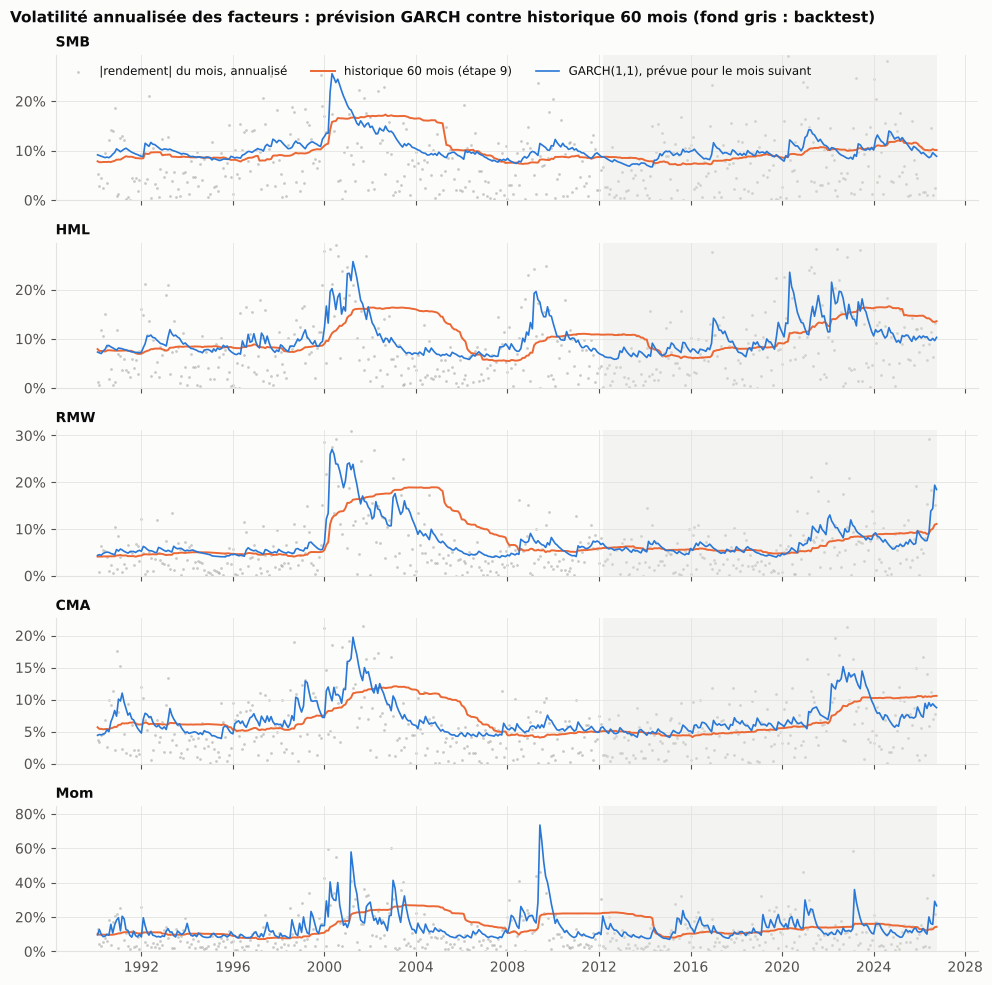

In [18]:
fig, axes = plt.subplots(5, 1, figsize=(10, 10), sharex=True)
d = mois_prev.to_timestamp(how="end")
for ax, k in zip(axes, FACT):
    ax.scatter(d, np.sqrt(12 * proxy[k]), s=4, color=GRIS, alpha=0.45, lw=0, label="|rendement| du mois, annualisé")
    ax.plot(d, np.sqrt(12 * historique[k].reindex(mois_prev)), color=ORANGE, lw=1.4, label="historique 60 mois (étape 9)")
    ax.plot(d, np.sqrt(12 * prev_garch[k]), color=BLEU, lw=1.2, label="GARCH(1,1), prévue pour le mois suivant")
    ax.axvspan(pd.Timestamp("2012-03-01"), d[-1], color=GRILLE, alpha=0.35, lw=0)
    ax.set_ylim(0, np.sqrt(12 * prev_garch[k]).max() * 1.15)
    ax.yaxis.set_major_formatter(virgule("{:.0%}"))
    ax.set_title(k, fontsize=10)
axes[0].legend(loc="upper left", ncol=3, fontsize=8.5)
axes[-1].xaxis.set_major_locator(mdates.YearLocator(4))
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
fig.suptitle("Volatilité annualisée des facteurs : prévision GARCH contre historique 60 mois (fond gris : backtest)",
             x=0.01, ha="left", fontsize=11, fontweight="bold")
fig.tight_layout()
sauver(fig, "garch_volatilites.png")
plt.show()

## 5. Les poids ERC avec la volatilité GARCH

Fin de chaque mois $t$ :

$$\Sigma_t = D_t\, C_t\, D_t, \qquad D_t = \text{diag}(\hat\sigma_{1,t+1|t}, \dots, \hat\sigma_{5,t+1|t})$$

- $\hat\sigma_{k,t+1|t}$ : volatilité prévue par le GARCH(1,1) pour le mois suivant ;
- $C_t$ : matrice de corrélation des 60 derniers mois, comme à l'étape 9.

Les poids ERC sont ensuite calculés sur $\Sigma_t$ avec le même solveur, puis le score final et le portefeuille sont construits exactement comme à l'étape 9.

In [19]:
def poids_erc_vol(vol):
    sortie = {}
    for m in mois:
        histo = facteurs.loc[:m, FACT].iloc[-60:]
        sigma = np.sqrt(vol.loc[m + 1, FACT].values)
        cov = np.outer(sigma, sigma) * histo.corr().values
        sortie[m] = poids_erc(cov)
    return pd.DataFrame(sortie, index=FACT).T


poids_garch = poids_erc_vol(prev_garch)
poids_ewma = poids_erc_vol(ewma)
scores["score_erc_garch"] = score_final(poids_garch)
scores["score_erc_ewma"] = score_final(poids_ewma)

resume_poids = pd.concat({"ERC historique (étape 9)": poids.describe().loc[["mean", "min", "max"]],
                          "ERC GARCH": poids_garch.describe().loc[["mean", "min", "max"]]}).rename(
    index={"mean": "moyenne", "min": "minimum", "max": "maximum"})
print(f"Corrélation entre les scores ERC historique et ERC GARCH : {scores['score_erc'].corr(scores['score_erc_garch']):.2f}")
print(f"Variation mensuelle moyenne des poids des facteurs (somme des |Δw|) : "
      f"historique {poids.diff().abs().sum(axis=1).mean():.1%}, GARCH {poids_garch.diff().abs().sum(axis=1).mean():.1%}")
resume_poids.style.format("{:.0%}")

Corrélation entre les scores ERC historique et ERC GARCH : 0.98
Variation mensuelle moyenne des poids des facteurs (somme des |Δw|) : historique 1.8%, GARCH 6.9%


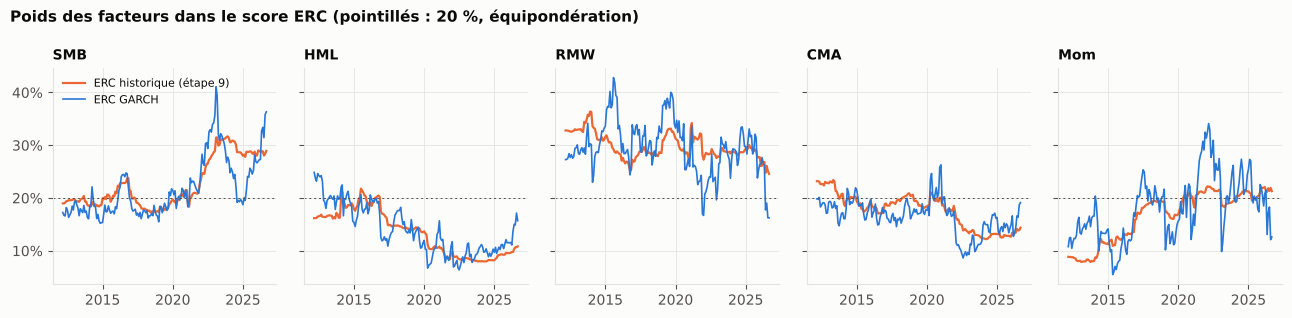

In [20]:
fig, axes = plt.subplots(1, 5, figsize=(13, 3.2), sharey=True)
d = poids.index.to_timestamp(how="end")
for ax, k in zip(axes, FACT):
    ax.plot(d, poids[k], color=ORANGE, lw=1.6, label="ERC historique (étape 9)")
    ax.plot(d, poids_garch[k], color=BLEU, lw=1.2, label="ERC GARCH")
    ax.axhline(0.2, color=TEXTE2, lw=0.7, ls=(0, (2, 3)))
    ax.set_title(k, fontsize=10)
    ax.yaxis.set_major_formatter(virgule("{:.0%}"))
    ax.xaxis.set_major_locator(mdates.YearLocator(5))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
axes[0].legend(loc="upper left", fontsize=8)
fig.suptitle("Poids des facteurs dans le score ERC (pointillés : 20 %, équipondération)", x=0.01, ha="left",
             fontsize=11, fontweight="bold")
fig.tight_layout()
sauver(fig, "garch_poids_erc.png")
plt.show()

## 6. Backtest

In [21]:
strategies = {
    "Score équipondéré (étape 9)": backtest(poids_cibles(scores["score_equipondere"])),
    "Score ERC historique (étape 9)": backtest(poids_cibles(scores["score_erc"])),
    "Score ERC GARCH": backtest(poids_cibles(scores["score_erc_garch"])),
}
reference = backtest(univers_capi())
periode = reference.index


def indicateurs(r):
    r = r.reindex(periode)
    exces = r - rf.reindex(periode)
    valeur = (1 + r).cumprod()
    return pd.Series({
        "rendement annuel": valeur.iloc[-1] ** (12 / len(r)) - 1,
        "volatilité": r.std() * np.sqrt(12),
        "Sharpe": exces.mean() / exces.std() * np.sqrt(12),
        "perte maximale": (valeur / valeur.cummax() - 1).min(),
    })


series = {k: v["net"] for k, v in strategies.items()}
series["Univers (capitalisation)"] = reference["net"]
series["SPY"] = rend_etf["SPY"]
resultats = pd.DataFrame({k: indicateurs(v) for k, v in series.items()}).T
resultats["rotation annuelle"] = [strategies[k]["rotation"].iloc[1:].mean() * 12 if k in strategies else np.nan
                                  for k in resultats.index]
print(f"Backtest : {periode[0]} à {periode[-1]}, {len(periode)} mois")
resultats.style.format({"rendement annuel": "{:.1%}", "volatilité": "{:.1%}", "Sharpe": "{:.2f}",
                        "perte maximale": "{:.1%}", "rotation annuelle": "{:.0%}"}, na_rep="")

Backtest : 2012-03 à 2026-08, 174 mois


,rendement annuel,volatilité,Sharpe,perte maximale,rotation annuelle
Score équipondéré (étape 9),15.6%,15.8%,0.90,-28.2%,315%
Score ERC historique (étape 9),14.7%,15.4%,0.87,-23.2%,278%
Score ERC GARCH,15.5%,15.1%,0.92,-22.5%,333%
Univers (capitalisation),15.1%,14.0%,0.96,-23.6%,
SPY,14.6%,14.0%,0.93,-23.9%,


### L'écart est-il significatif ?

Rendement actif net de l'ERC GARCH contre l'ERC historique de l'étape 9 (le test direct de l'amélioration), et contre l'univers. Mêmes outils qu'à l'étape 9.

In [22]:
lignes = []
g = strategies["Score ERC GARCH"]["net"]
for nom_bench, bench in [("Score ERC historique (étape 9)", strategies["Score ERC historique (étape 9)"]["net"]),
                         ("Univers (capitalisation)", reference["net"])]:
    a = g - bench
    moy, t, p = test_moyenne(a)
    ic_actif, ic_sharpe = bootstrap(g, bench)
    lignes.append({"comparé à": nom_bench, "rendement actif annuel": 12 * moy, "écart de suivi": a.std() * np.sqrt(12),
                   "t (Newey-West)": t, "p-valeur": p, "IC 95 % rendement actif": f"[{ic_actif[0]:+.1%} ; {ic_actif[1]:+.1%}]",
                   "écart de Sharpe": sharpe(g, rf.reindex(periode)) - sharpe(bench, rf.reindex(periode)),
                   "IC 95 % écart de Sharpe": f"[{ic_sharpe[0]:+.2f} ; {ic_sharpe[1]:+.2f}]"})
pd.DataFrame(lignes).set_index("comparé à").style.format(
    {"rendement actif annuel": "{:+.2%}", "écart de suivi": "{:.1%}", "t (Newey-West)": "{:+.2f}", "p-valeur": "{:.2f}",
     "écart de Sharpe": "{:+.2f}"})

,rendement actif annuel,écart de suivi,t (Newey-West),p-valeur,IC 95 % rendement actif,écart de Sharpe,IC 95 % écart de Sharpe
comparé à,,,,,,,
Score ERC historique (étape 9),+0.65%,2.7%,+1.11,0.27,[-0.4% ; +1.9%],+0.06,[-0.02 ; +0.16]
Univers (capitalisation),+0.53%,5.9%,+0.30,0.76,[-2.8% ; +3.8%],-0.04,[-0.29 ; +0.19]


### Robustesse : sous-périodes, frais, autre prévision de volatilité

In [23]:
lignes = {}
a_tout = strategies["Score ERC GARCH"]["net"] - strategies["Score ERC historique (étape 9)"]["net"]
for sp, (d, f) in {"2012-2019": ("2012-03", "2019-12"), "2020-2026": ("2020-01", "2026-08")}.items():
    moy, t, _ = test_moyenne(a_tout.loc[d:f])
    lignes[sp] = {"écart annuel GARCH − historique": 12 * moy, "t (Newey-West)": t}
pd.DataFrame(lignes).T.style.format({"écart annuel GARCH − historique": "{:+.2%}", "t (Newey-West)": "{:+.2f}"})

,écart annuel GARCH − historique,t (Newey-West)
2012-2019,+0.62%,+1.01
2020-2026,+0.70%,+0.66


In [24]:
bt_g, bt_h = strategies["Score ERC GARCH"], strategies["Score ERC historique (étape 9)"]
pd.DataFrame({"écart annuel GARCH − historique": [12 * ((bt_g["brut"] - pb / 1e4 * bt_g["rotation"])
                                                       - (bt_h["brut"] - pb / 1e4 * bt_h["rotation"])).mean()
                                                 for pb in [0, 10, 25, 50]]},
             index=pd.Index([0, 10, 25, 50], name="frais (points de base)")).style.format("{:+.2%}")

,écart annuel GARCH − historique
frais (points de base),
0,+0.71%
10,+0.65%
25,+0.57%
50,+0.44%


In [25]:
# Même test avec la volatilité EWMA à la place du GARCH
bt_e = backtest(poids_cibles(scores["score_erc_ewma"]))
a = bt_e["net"] - bt_h["net"]
moy, t, p = test_moyenne(a)
print(f"ERC EWMA − ERC historique : {12 * moy:+.2%} par an, t = {t:+.2f}")
print(f"ERC EWMA − ERC GARCH : {12 * (bt_e['net'] - bt_g['net']).mean():+.2%} par an, "
      f"t = {test_moyenne(bt_e['net'] - bt_g['net'])[1]:+.2f}")

ERC EWMA − ERC historique : +0.66% par an, t = +1.51
ERC EWMA − ERC GARCH : +0.00% par an, t = +0.00


## 7. Graphique

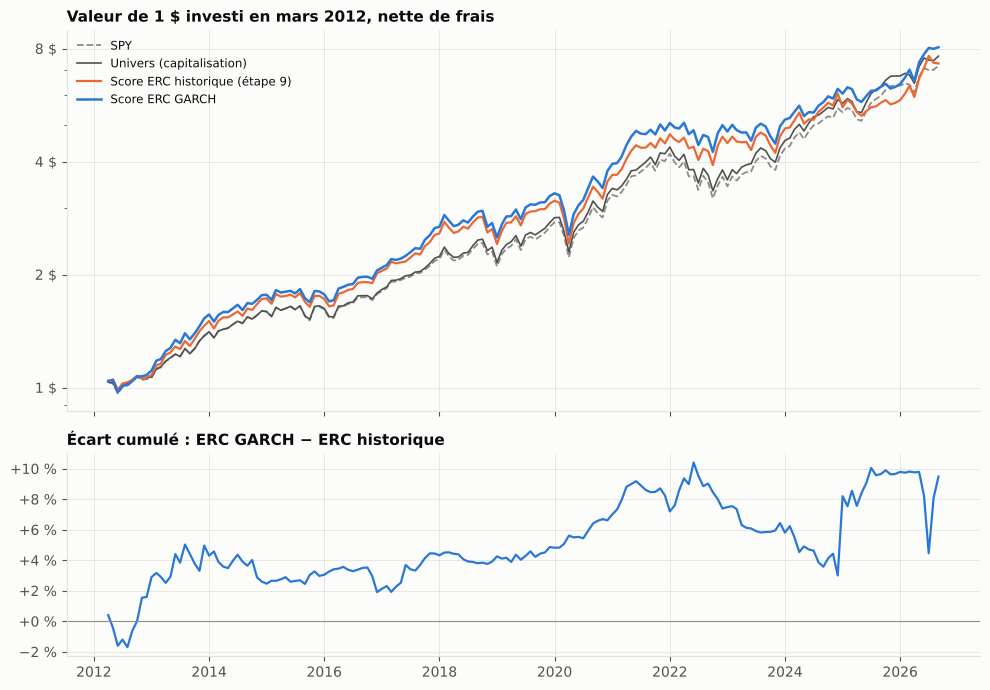

In [26]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 7), sharex=True, gridspec_kw={"height_ratios": [3, 1.6]})
d = periode.to_timestamp(how="end")
traces = [("SPY", GRIS, "--", 1.3), ("Univers (capitalisation)", TEXTE2, "-", 1.2),
          ("Score ERC historique (étape 9)", ORANGE, "-", 1.6), ("Score ERC GARCH", BLEU, "-", 1.8)]
for nom, couleur, style, lw in traces:
    ax1.plot(d, (1 + series[nom].reindex(periode)).cumprod(), color=couleur, ls=style, lw=lw, label=nom)
ax2.plot(d, 100 * a_tout.reindex(periode).cumsum(), color=BLEU, lw=1.6)
ax2.axhline(0, color=GRIS, lw=0.8)
ax1.set_yscale("log")
ax1.set_yticks([1, 2, 4, 8])
ax1.yaxis.set_major_formatter(virgule("{:.0f} $"))
ax1.yaxis.set_minor_formatter(plt.NullFormatter())
ax1.set_title("Valeur de 1 $ investi en mars 2012, nette de frais")
ax1.legend(loc="upper left", fontsize=8.5)
ax2.yaxis.set_major_formatter(virgule("{:+.0f} %"))
ax2.set_title("Écart cumulé : ERC GARCH − ERC historique")
ax2.xaxis.set_major_locator(mdates.YearLocator(2))
ax2.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
fig.tight_layout()
sauver(fig, "garch_backtest.png")
plt.show()